In [3]:
#import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [7]:
#Load the dataset

url = "https://raw.githubusercontent.com/deyyfahr-hub/Portofolio/refs/heads/main/Dataset/Walmart_Sales.csv?token=GHSAT0AAAAAAEO5AIZIHYGXUK6R34BRDDS62XMHC5A"
df = pd.read_csv(url)
df


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [23]:
#Data Overview
print("Shape :", df.shape)
df.info()
df.describe()

Shape : (6435, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   store         6435 non-null   int64         
 1   date          6435 non-null   datetime64[ns]
 2   weekly_sales  6435 non-null   float64       
 3   holiday_flag  6435 non-null   int64         
 4   temperature   6435 non-null   float64       
 5   fuel_price    6435 non-null   float64       
 6   cpi           6435 non-null   float64       
 7   unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,2011-06-17 00:00:00,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
min,1.000000,2010-02-05 00:00:00,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,2010-10-08 00:00:00,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,2011-06-17 00:00:00,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,2012-02-24 00:00:00,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,2012-10-26 00:00:00,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885


In [13]:
#Check for missing values
missing_values = df.isnull().sum()
print("Missing Values:")
print(missing_values)

Missing Values:
Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


In [15]:
#check for duplicates
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [17]:
#Data Cleaning
df.columns = (
    df.columns
    .str.strip() #remove leading and trailing whitespace
    .str.lower() #convert to lowercase
    .str.replace(" ", "_") #replace spaces with underscores
)

df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [24]:
df['date'] = pd.to_datetime(df['date'], dayfirst=True) #convert date column to datetime format

In [30]:
df['year'] = df['date'].dt.year #extract year from date
df['month'] = df['date'].dt.month_name() #extract month name from date
df['month_num'] = df['date'].dt.month #extract month number from date
df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,month_num
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,February,2
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,February,2
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,February,2
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,February,2
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,March,3


Exploratory Data Analysis

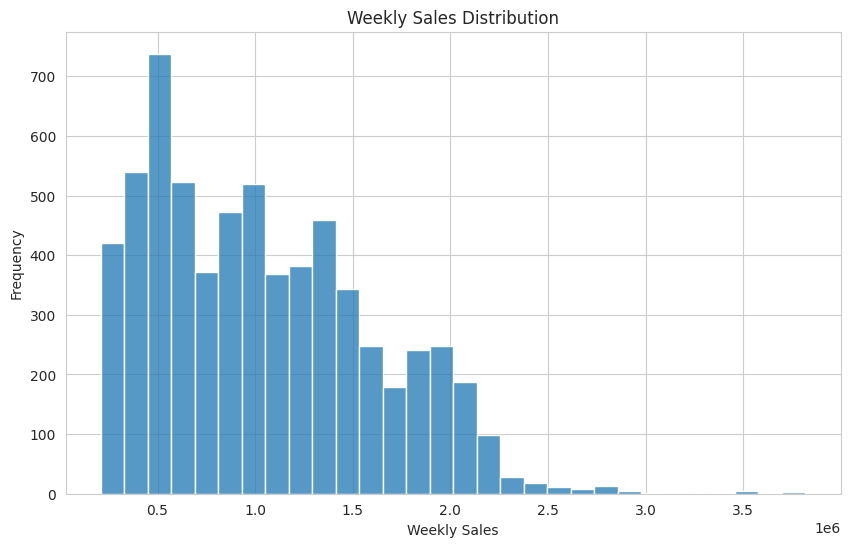

In [33]:
#sales distribution
sns.histplot(df['weekly_sales'], bins=30)

plt.title('Weekly Sales Distribution')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')
plt.show()

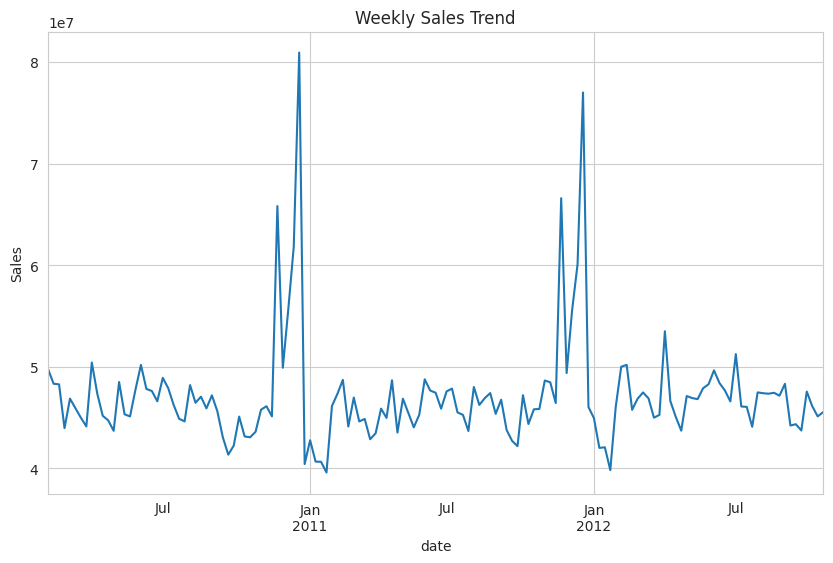

In [38]:
#sales trend over time
sales_trend = df.groupby('date')['weekly_sales'].sum()
sales_trend.plot()
plt.title("Weekly Sales Trend")
plt.ylabel("Sales")
plt.show()

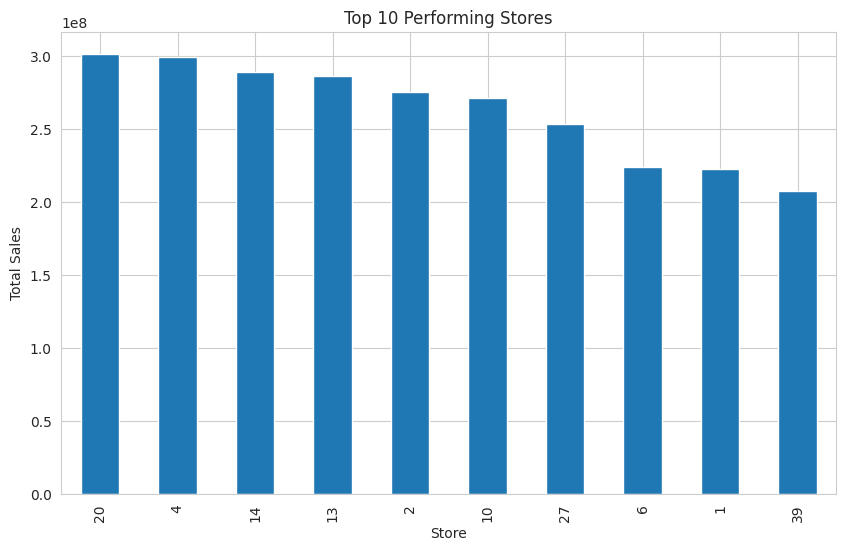

In [41]:
#Top performing stores
top_stores = (
    df.groupby('store')['weekly_sales']
        .sum()
        .sort_values(ascending=False)
        .head(10)
)
top_stores.plot(kind='bar')
plt.title("Top 10 Performing Stores")
plt.ylabel("Total Sales")
plt.xlabel("Store")
plt.show()

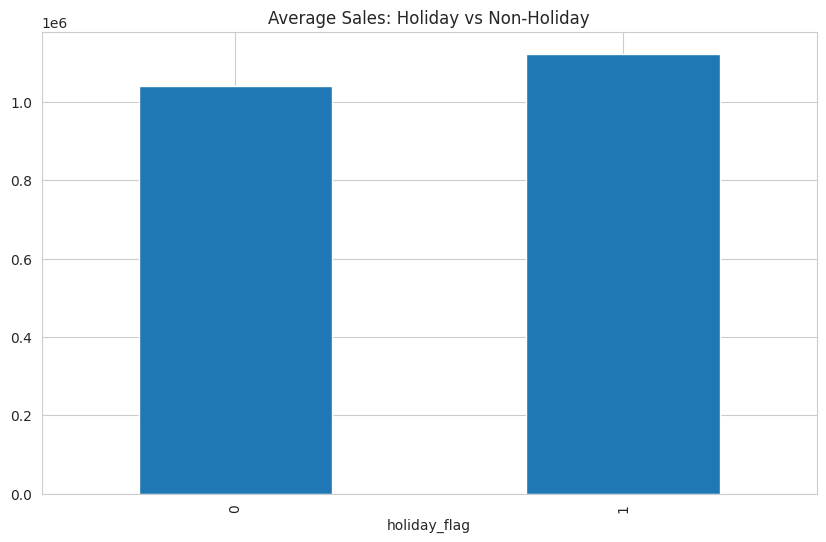

In [50]:
#holiday vs Non-Holiday Sales
holiday_sales = (
    df.groupby('holiday_flag')['weekly_sales']
    .mean()
)

holiday_sales.plot(kind='bar')

plt.title("Average Sales: Holiday vs Non-Holiday")
plt.show()

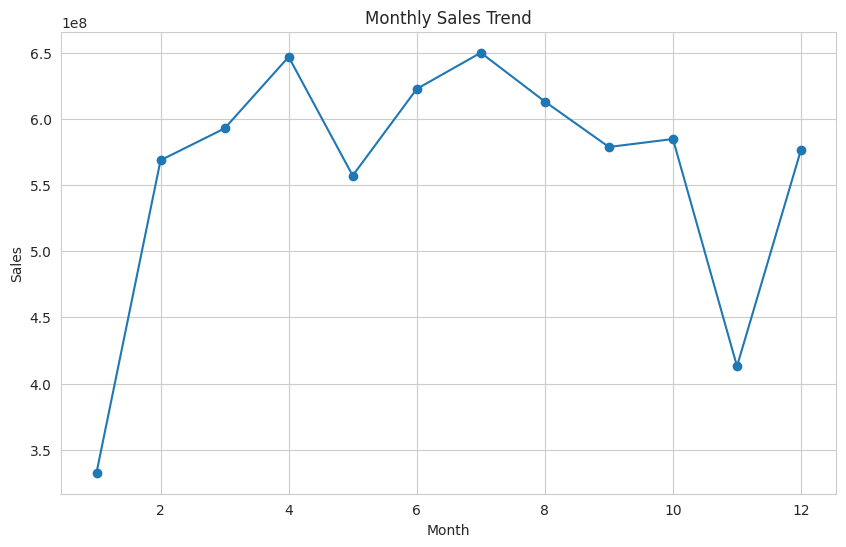

In [55]:
monthly_sales = (
    df.groupby('month_num')['weekly_sales']
    .sum()
)

monthly_sales.plot(marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

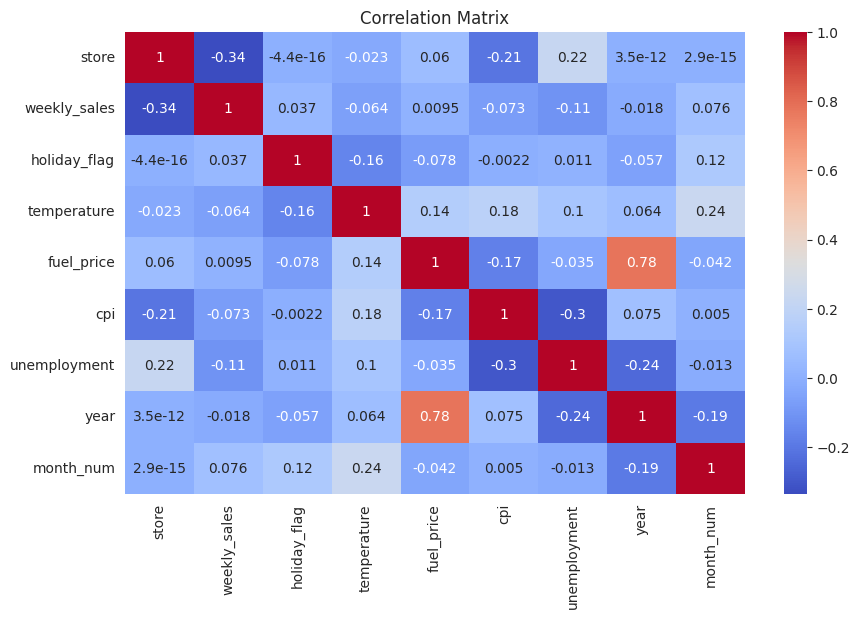

In [59]:
#correlation analysis
correlation_matrix = df.corr(numeric_only=True)
correlation_matrix
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [66]:
#KPIs Summary
total_sales = df['weekly_sales'].sum()
avg_sales = df['weekly_sales'].mean()
max_sales = df['weekly_sales'].max()
min_sales = df['weekly_sales'].min()
best_store = df.groupby('store')['weekly_sales'].sum().idxmax()
print(f"Total Sales : ${total_sales:,.0f}")
print(f"Average Sales: ${avg_sales:,.0f}")
print(f"Maximum Sales: ${max_sales:,.0f}")
print(f"Minimum Sales: ${min_sales:,.0f}")
print(f"Best Performing Store: {best_store}")

Total Sales : $6,737,218,987
Average Sales: $1,046,965
Maximum Sales: $3,818,686
Minimum Sales: $209,986
Best Performing Store: 20


In [67]:
# Business insights
holiday_avg = holiday_sales.loc[1]
nonholiday_avg = holiday_sales.loc[0]
holiday_uplift = (holiday_avg / nonholiday_avg - 1) * 100

best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()
best_store_sales = top_stores.iloc[0]

sales_correlations = correlation_matrix['weekly_sales'].drop('weekly_sales')
strongest_factor = sales_correlations.abs().idxmax()
strongest_correlation = sales_correlations[strongest_factor]

print("BUSINESS INSIGHTS")
print(f"• Holiday-week average sales were {holiday_uplift:.1f}% higher than non-holiday weeks.")
print(f"• Store {top_stores.index[0]} led total sales at ${best_store_sales:,.0f}.")
print(f"• Month {best_month} had the highest recorded total sales at ${best_month_sales:,.0f}.")
print(
    f"• The strongest numeric association with weekly sales was "
    f"{strongest_factor} (correlation: {strongest_correlation:.2f}); "
    "this indicates association, not causation."
)
print("• Interpret monthly totals cautiously: the dataset covers partial years.")

BUSINESS INSIGHTS
• Holiday-week average sales were 7.8% higher than non-holiday weeks.
• Store 20 led total sales at $301,397,792.
• Month 7 had the highest recorded total sales at $650,000,977.
• The strongest numeric association with weekly sales was store (correlation: -0.34); this indicates association, not causation.
• Interpret monthly totals cautiously: the dataset covers partial years.
